# Advertising Sales Prediction Using Machine Learning

## 1. Project Overview

This project aims to analyse advertising expenditure across different marketing channels and predict product sales using Machine Learning regression algorithms.

The project explores multiple regression techniques, evaluates their performance using different metrics, and identifies the most suitable model for predicting sales.

## 2. Project Objectives

- Analyse the relationship between advertising expenditure and sales.
- Perform data cleaning and Exploratory Data Analysis (EDA).
- Implement different regression algorithms.
- Evaluate models using MAE, MSE, RMSE and R² Score.
- Compare model performance and analyse feature importance.
- Select the most suitable regression algorithm for sales prediction.

## Key Features

- **Exploratory Data Analysis:** Analyses advertising expenditure, sales distributions, correlations and relationships using statistical methods and visualisations.
- **Data Preprocessing:** Checks for missing values, duplicate records and unnecessary columns to prepare the dataset.
- **Multiple Regression Algorithms:** Implements Simple Linear Regression, Multiple Linear Regression, Polynomial Regression and Random Forest Regression.
- **Model Evaluation:** Evaluates algorithms using MAE, MSE, RMSE and R² Score.
- **Performance Comparison:** Compares the predictive performance of all four algorithms using a common evaluation approach.
- **Cross-Validation:** Uses 5-fold cross-validation to examine model performance and consistency.
- **Feature Importance:** Analyses the contribution of TV, Radio and Newspaper advertising features using Random Forest.
- **Model Selection:** Identifies Polynomial Regression as the best-performing model based on the current test-set and cross-validation results.
- **Sales Prediction:** Predicts sales using new advertising expenditure values.
- **Model Saving:** Saves the selected trained model using Joblib for future predictions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

## 3. Dataset Loading

The Advertising dataset contains information about advertising expenditure across three marketing channels: TV, Radio and Newspaper. The target variable, Sales, represents the sales generated from these advertising investments.

The dataset will be used to explore relationships between advertising expenditure and sales and to build regression models.

In [2]:
df = pd.read_csv(r"D:\Data science\datasets\csv\Advertising.csv")

df.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


## 4. Data Understanding

In this section, we examine the structure, dimensions and statistical properties of the dataset. This helps us understand the available features and identify potential data quality issues before performing further analysis.

In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (200, 5)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newspaper   200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [5]:
df.describe()

,Unnamed: 0,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [6]:
df.isnull().sum()

Unnamed: 0    0
TV            0
radio         0
newspaper     0
sales         0
dtype: int64

In [7]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


## 5. Data Cleaning and Preprocessing

Data cleaning is an important step in preparing the dataset for Machine Learning. In this section, we check for missing values, duplicate records and unnecessary columns to ensure the data is suitable for analysis and model training.

In [8]:
if "Unnamed: 0" in df.columns:
    df.drop(columns=["Unnamed: 0"], inplace=True)

df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [9]:
print("Missing values before cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64


In [10]:
df.drop_duplicates(inplace=True)

print("Dataset shape after cleaning:", df.shape)
print("Duplicate records:", df.duplicated().sum())

Dataset shape after cleaning: (200, 4)
Duplicate records: 0


In [11]:
print(df.dtypes)

TV           float64
radio        float64
newspaper    float64
sales        float64
dtype: object


## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the patterns, distributions and relationships within the dataset. In this section, we analyse advertising expenditure and sales using statistical summaries and visualisations to identify useful insights before applying regression algorithms.

### 6.1 Distribution Analysis

Distribution analysis helps us understand how the values of each numerical feature are spread across the dataset. Histograms and distribution plots are used to identify patterns, skewness and possible outliers.

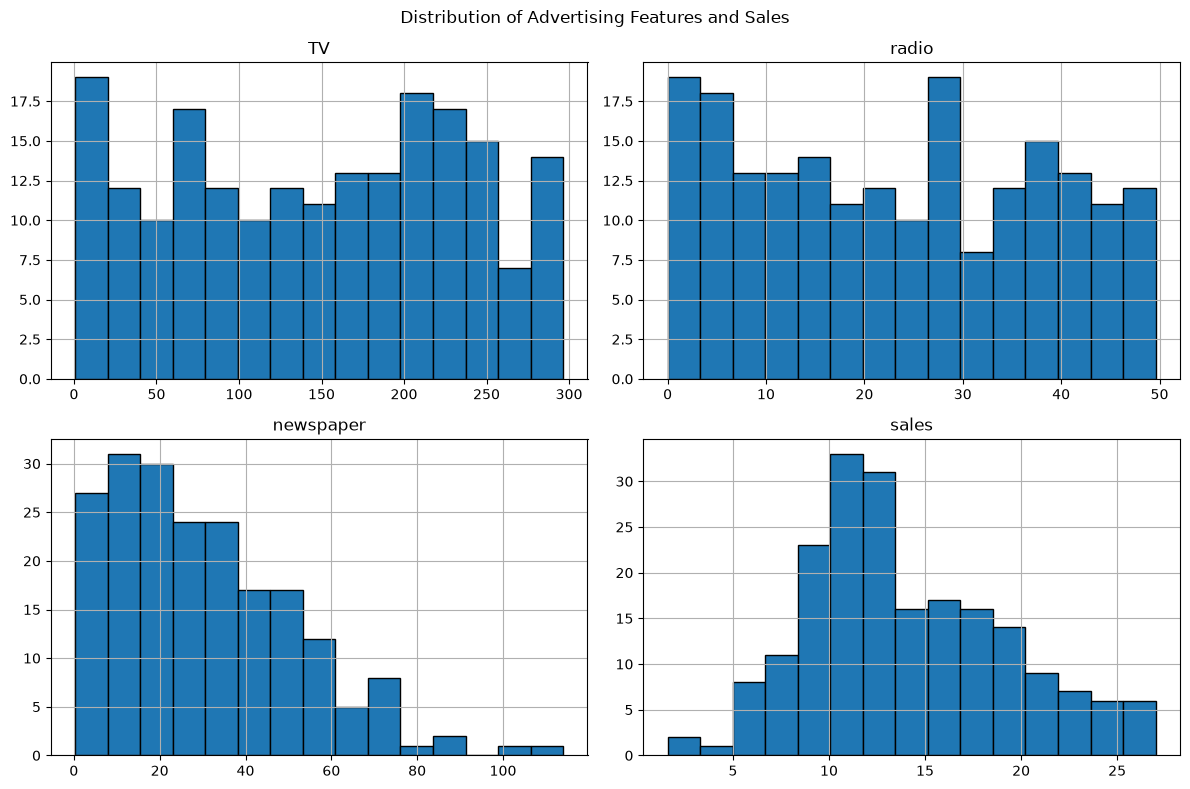

In [12]:
df.hist(figsize=(12, 8), bins=15, edgecolor="black")

plt.suptitle("Distribution of Advertising Features and Sales")
plt.tight_layout()
plt.show()

### 6.2 Outlier Analysis

Boxplots are used to identify potential outliers in numerical features. They display the median, quartiles and values that fall outside the typical data range.

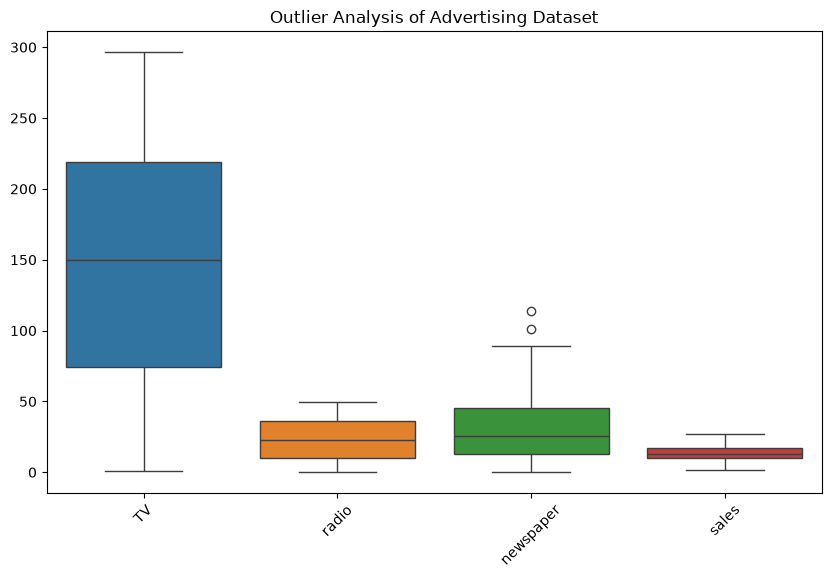

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df)

plt.title("Outlier Analysis of Advertising Dataset")
plt.xticks(rotation=45)
plt.show()

### 6.3 Correlation Analysis

Correlation analysis measures the strength and direction of relationships between numerical variables. It helps identify which advertising channels have stronger relationships with Sales and provides useful insights for feature selection.

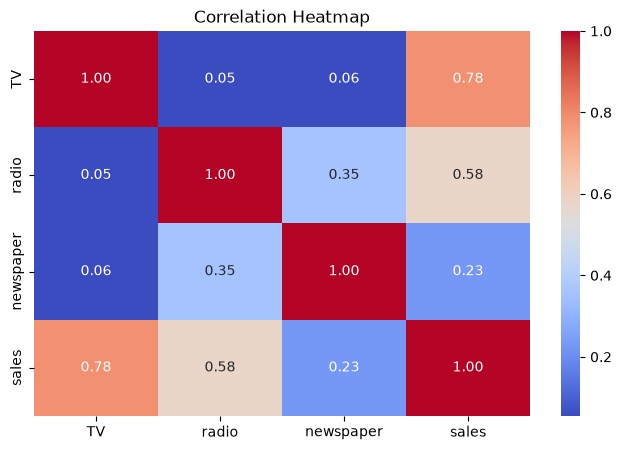

In [14]:
correlation = df.corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

## 7. Feature Selection

Feature selection involves identifying the input variables that are useful for predicting the target variable. In this project, TV, Radio and Newspaper advertising expenditures are considered as independent variables, while Sales is the dependent variable.

### 7.1 Defining Features and Target

The independent variables represent advertising expenditure across different channels, while the dependent variable represents the sales generated. These variables will be used as inputs and outputs for the regression models.

In [15]:
X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

print("Independent Variables:")
display(X.head())

print("Dependent Variable:")
display(y.head())

Independent Variables:


,TV,radio,newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


Dependent Variable:


0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: sales, dtype: float64

### 7.2 Feature Correlation with Target

Analysing the correlation between each independent variable and Sales helps us understand the strength of their individual relationships. This provides an initial indication of which advertising channels may be useful for prediction.

In [16]:
sales_correlation = df.corr()["sales"].drop("sales")

print(sales_correlation.sort_values(ascending=False))

TV           0.782224
radio        0.576223
newspaper    0.228299
Name: sales, dtype: float64


### 7.3 Feature Relationship Analysis

Scatter plots help visualise how each advertising channel relates to Sales. They can reveal linear or nonlinear patterns and help us understand the suitability of different regression algorithms.

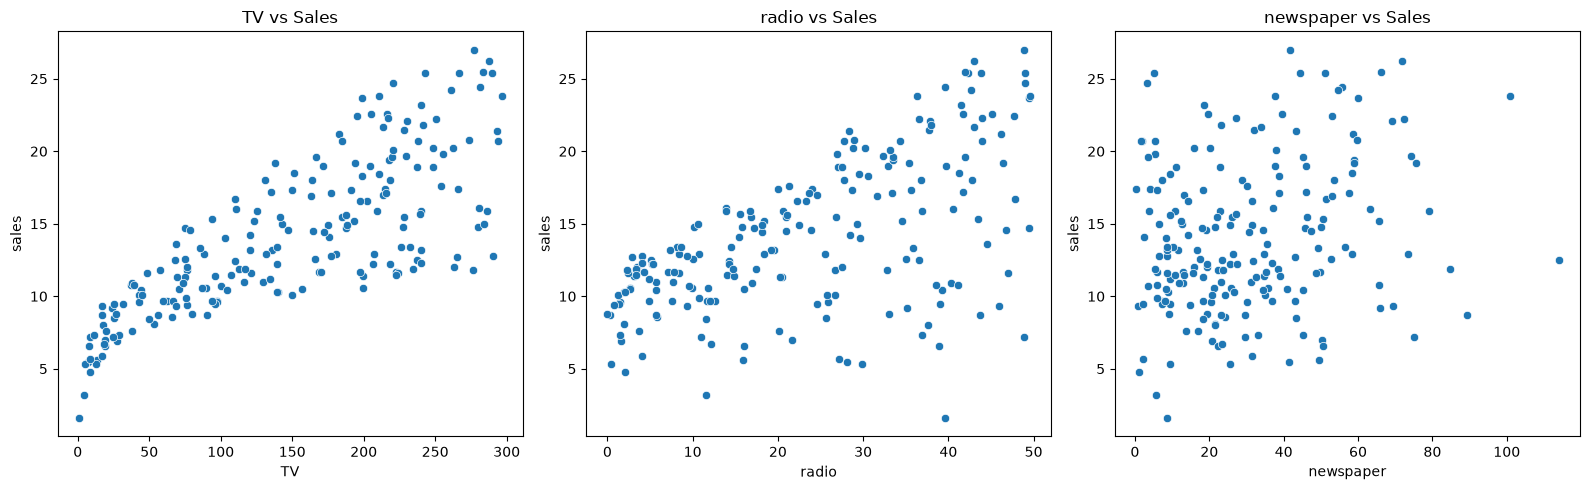

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

features = ["TV", "radio", "newspaper"]

for i, feature in enumerate(features):
    sns.scatterplot(data=df, x=feature, y="sales", ax=axes[i])
    axes[i].set_title(f"{feature} vs Sales")

plt.tight_layout()
plt.show()

### 6.4 EDA Findings and Observations

- TV advertising shows a positive relationship with Sales, indicating that higher TV expenditure is generally associated with increased sales.
- Radio advertising also shows a positive relationship with Sales.
- Newspaper advertising shows a comparatively weaker relationship with Sales.
- The correlation analysis suggests that TV and Radio are useful predictors of Sales.

These observations provide an initial understanding of the dataset and help guide the selection and evaluation of regression algorithms.

## 8. Train-Test Split

The dataset is divided into training and testing subsets to evaluate how well the machine learning models perform on unseen data. The training data is used to build the models, while the testing data is used to measure their predictive performance.

In [18]:
X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (160, 3)
Testing features: (40, 3)
Training target: (160,)
Testing target: (40,)


## 9. Model Implementation and Evaluation

In this section, different regression algorithms are implemented and evaluated using a common set of performance metrics. This approach ensures a consistent comparison and helps identify the most suitable model for predicting sales.

### 9.1 Model Evaluation Metrics

The regression models are evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE) and R² Score. These metrics help measure prediction errors and determine how well each model explains the variation in Sales.

In [19]:
def evaluate_model(model, X_test, y_test):

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

In [20]:
results = []

### 9.2 Simple Linear Regression

Simple Linear Regression is a supervised learning algorithm that predicts a dependent variable using one independent variable. It establishes a straight-line relationship between the input feature and the target variable.

In this project, TV advertising expenditure is used to predict Sales.

In [21]:
# Select TV as the only input feature
X_train_simple = X_train[["TV"]]
X_test_simple = X_test[["TV"]]

# Create and train the model
simple_model = LinearRegression()

simple_model.fit(X_train_simple, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.05]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['TV']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.12
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [22]:
simple_metrics = evaluate_model(
    simple_model,
    X_test_simple,
    y_test
)

print("Simple Linear Regression Results:")
print(simple_metrics)

results.append({
    "Algorithm": "Simple Linear Regression",
    **simple_metrics
})

Simple Linear Regression Results:
{'MAE': 2.444420003751042, 'MSE': 10.204654118800956, 'RMSE': np.float64(3.194472431998898), 'R2 Score': 0.6766954295627076}


#### Actual vs Predicted Sales

This visualisation compares the actual sales values with the predictions generated by the Simple Linear Regression model. Points closer to the reference line indicate more accurate predictions.

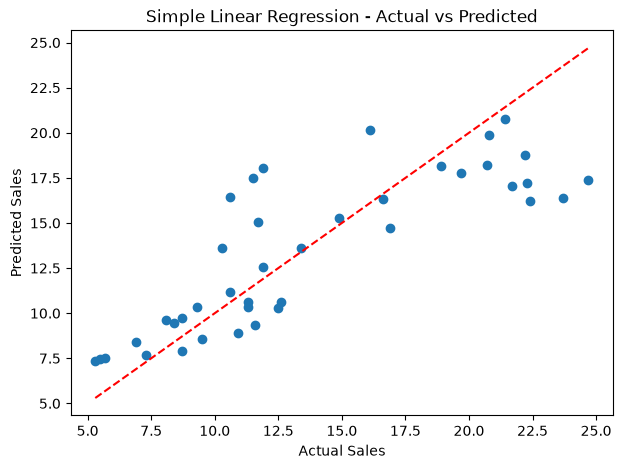

In [23]:
y_pred_simple = simple_model.predict(X_test_simple)

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_simple)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Simple Linear Regression - Actual vs Predicted")

plt.show()

### 9.3 Multiple Linear Regression

Multiple Linear Regression predicts a dependent variable using two or more independent variables. It analyses how multiple input features contribute to the prediction of the target variable.

In this project, TV, Radio and Newspaper advertising expenditures are used together to predict Sales.

In [24]:
multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.04,0.19,0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','radio','newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.979
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [25]:
multiple_metrics = evaluate_model(
    multiple_model,
    X_test,
    y_test
)

print("Multiple Linear Regression Results:")
print(multiple_metrics)

results.append({
    "Algorithm": "Multiple Linear Regression",
    **multiple_metrics
})

Multiple Linear Regression Results:
{'MAE': 1.4607567168117603, 'MSE': 3.1740973539761033, 'RMSE': np.float64(1.78159966153345), 'R2 Score': 0.899438024100912}


#### Actual vs Predicted Sales

This plot evaluates how closely the Multiple Linear Regression model's predictions match the actual sales values. It helps visually assess the model's prediction accuracy.

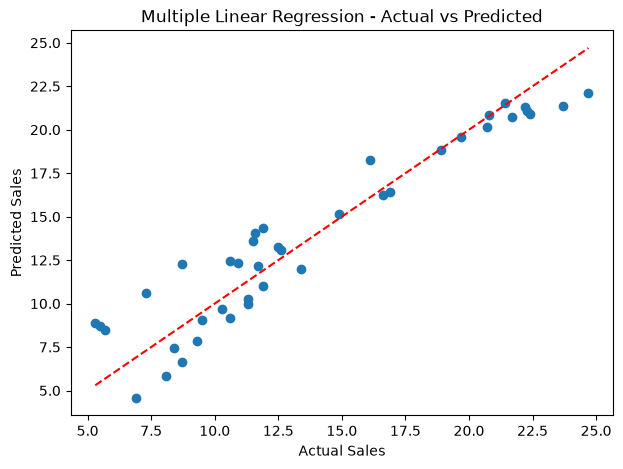

In [26]:
y_pred_multiple = multiple_model.predict(X_test)

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_multiple)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Multiple Linear Regression - Actual vs Predicted")

plt.show()

In [27]:
comparison_df = pd.DataFrame(results)

comparison_df

,Algorithm,MAE,MSE,RMSE,R2 Score
0,Simple Linear Regression,2.444420,10.204654,3.194472,0.676695
1,Multiple Linear Regression,1.460757,3.174097,1.781600,0.899438


### 9.4 Polynomial Regression

Polynomial Regression is an extension of Linear Regression that models nonlinear relationships by introducing polynomial powers of input features. It helps capture curved patterns in the data that a straight-line model may not represent effectively.

In [28]:
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomialfeatures', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['TV','radio','newspaper']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [29]:
poly_metrics = evaluate_model(
    poly_model,
    X_test,
    y_test
)

print("Polynomial Regression Results:")
print(poly_metrics)

results.append({
    "Algorithm": "Polynomial Regression",
    **poly_metrics
})

Polynomial Regression Results:
{'MAE': 0.5261794444043822, 'MSE': 0.4129102285379007, 'RMSE': np.float64(0.6425809120553618), 'R2 Score': 0.9869181490609604}


#### Actual vs Predicted Sales

This visualisation compares actual sales values with predictions from the Polynomial Regression model. It helps evaluate whether the model captures more complex relationships between advertising expenditure and sales.

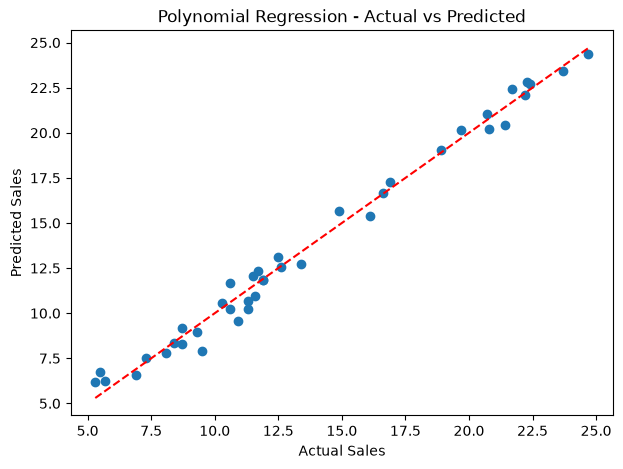

In [30]:
y_pred_poly = poly_model.predict(X_test)

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_poly)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Polynomial Regression - Actual vs Predicted")

plt.show()

### 9.5 Random Forest Regression

Random Forest Regression is an ensemble learning algorithm that combines multiple Decision Trees to generate predictions. It uses the average of individual tree predictions to improve stability, capture complex patterns and reduce overfitting.

In [31]:
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [32]:
rf_metrics = evaluate_model(
    random_forest_model,
    X_test,
    y_test
)

print("Random Forest Regression Results:")
print(rf_metrics)

results.append({
    "Algorithm": "Random Forest Regression",
    **rf_metrics
})

Random Forest Regression Results:
{'MAE': 0.6203249999999988, 'MSE': 0.5909259749999988, 'RMSE': np.float64(0.7687170968568338), 'R2 Score': 0.9812782416450916}


#### Actual vs Predicted Sales

This plot compares the actual sales values with the predictions generated by the Random Forest model. It helps assess how effectively the ensemble algorithm captures relationships in the advertising dataset.

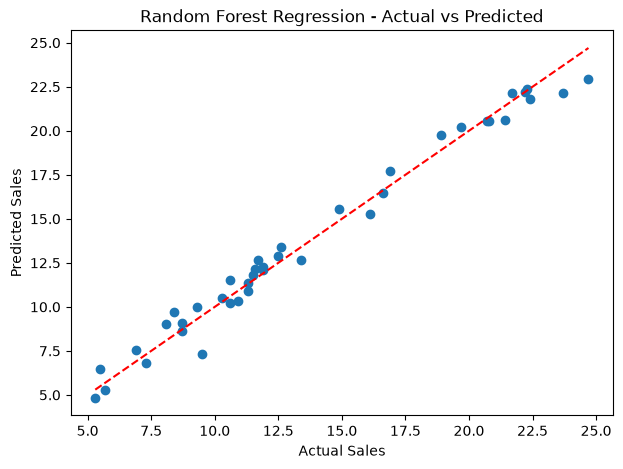

In [33]:
y_pred_rf = random_forest_model.predict(X_test)

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_rf)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Random Forest Regression - Actual vs Predicted")

plt.show()

In [34]:
comparison_df = pd.DataFrame(results)

comparison_df

,Algorithm,MAE,MSE,RMSE,R2 Score
0,Simple Linear Regression,2.444420,10.204654,3.194472,0.676695
1,Multiple Linear Regression,1.460757,3.174097,1.781600,0.899438
2,Polynomial Regression,0.526179,0.412910,0.642581,0.986918
3,Random Forest Regression,0.620325,0.590926,0.768717,0.981278


### 9.6 Model Performance Comparison

The performance of all four regression algorithms is compared using evaluation metrics. Visual comparisons of MAE, RMSE and R² scores help identify the models with better predictive accuracy and lower prediction errors.

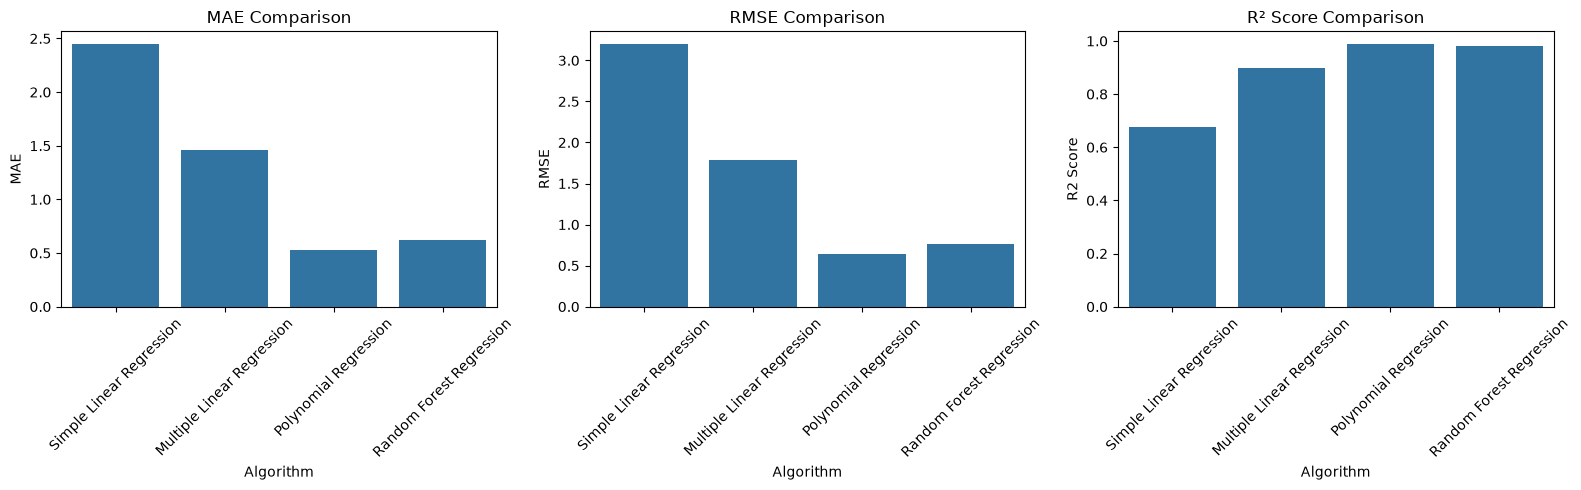

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(data=comparison_df, x="Algorithm", y="MAE", ax=axes[0])
axes[0].set_title("MAE Comparison")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(data=comparison_df, x="Algorithm", y="RMSE", ax=axes[1])
axes[1].set_title("RMSE Comparison")
axes[1].tick_params(axis="x", rotation=45)

sns.barplot(data=comparison_df, x="Algorithm", y="R2 Score", ax=axes[2])
axes[2].set_title("R² Score Comparison")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 10. Feature Importance Analysis

Feature importance analysis helps identify the input variables that contribute most to model predictions. In this project, we examine the importance of TV, Radio and Newspaper advertising expenditure using the Random Forest model.

,Feature,Importance
0,TV,0.624810
1,radio,0.362214
2,newspaper,0.012976


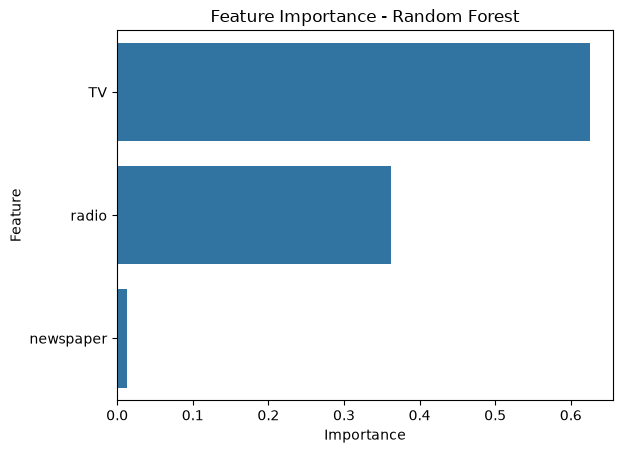

In [36]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.show()

## 11. Cross-Validation

Cross-validation is a model evaluation technique that divides the training data into multiple subsets to assess model performance across different data splits. It helps determine whether a model performs consistently rather than depending on a single train-test split.

In [37]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Simple Linear Regression": (
        LinearRegression(),
        X_train[["TV"]]
    ),

    "Multiple Linear Regression": (
        LinearRegression(),
        X_train
    ),

    "Polynomial Regression": (
        make_pipeline(
            PolynomialFeatures(degree=2, include_bias=False),
            LinearRegression()
        ),
        X_train
    ),

    "Random Forest Regression": (
        RandomForestRegressor(
            n_estimators=100,
            random_state=42
        ),
        X_train
    )
}

In [38]:
cv_results = []

for name, (model, features) in models.items():

    scores = cross_val_score(
        model,
        features,
        y_train,
        cv=cv,
        scoring="r2"
    )

    cv_results.append({
        "Algorithm": name,
        "Mean CV R2": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

cv_df.sort_values(
    by="Mean CV R2",
    ascending=False
)

,Algorithm,Mean CV R2,Standard Deviation
2,Polynomial Regression,0.977835,0.017043
3,Random Forest Regression,0.966255,0.013162
1,Multiple Linear Regression,0.870265,0.071844
0,Simple Linear Regression,0.514143,0.208333


## 12. Final Model Selection

The final model is selected by considering test-set performance, cross-validation results and prediction consistency. Models with higher R² scores, lower prediction errors and reliable validation performance are preferred for the final sales prediction task.

In [39]:
best_model_name = cv_df.loc[
    cv_df["Mean CV R2"].idxmax(),
    "Algorithm"
]

print("Best Model Based on Cross-Validation:", best_model_name)

Best Model Based on Cross-Validation: Polynomial Regression


## 13. Saving the Final Model

The selected regression model is saved for future use. This allows predictions to be generated without repeating the complete model training process.

In [40]:
import joblib

final_model = poly_model

joblib.dump(final_model, "advertising_sales_model.pkl")

print("Final model saved successfully!")

Final model saved successfully!


## 14. Sales Prediction Using New Data

In this section, the selected Polynomial Regression model is used to predict sales based on new advertising expenditure values. This demonstrates how the trained model can be applied to previously unseen data.

In [41]:
new_data = pd.DataFrame({
    "TV": [150],
    "radio": [25],
    "newspaper": [20]
})

predicted_sales = final_model.predict(new_data)

print("New Advertising Budget:")
display(new_data)

print("Predicted Sales:", predicted_sales[0])

New Advertising Budget:


,TV,radio,newspaper
0,150,25,20


Predicted Sales: 15.13929891727564


## 15. Final Model Performance

The selected Polynomial Regression model is evaluated on the testing dataset to measure its predictive performance. Its evaluation metrics are used to summarise how accurately the model predicts sales on unseen data.

In [42]:
final_metrics = evaluate_model(final_model, X_test, y_test)

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

MAE: 0.5262
MSE: 0.4129
RMSE: 0.6426
R2 Score: 0.9869


## Project Limitations

- **Limited Dataset:** The project uses a relatively small dataset containing only 200 records, which may limit the model's ability to generalise to larger and more diverse datasets.
- **Limited Features:** Only TV, Radio and Newspaper advertising expenditures are considered. Other factors affecting sales, such as product pricing, customer preferences and market competition, are not included.
- **Historical Data:** The predictions are based on historical advertising and sales data and may not accurately represent future market conditions.
- **Model Dependency:** The model's performance depends on the quality and characteristics of the available dataset.
- **Limited Hyperparameter Tuning:** The algorithms use selected configurations and have not undergone extensive hyperparameter optimisation.
- **No External Validation:** The model has not yet been tested using an independent external dataset.
- **Correlation vs Causation:** Relationships identified between advertising expenditure and sales do not necessarily establish a direct cause-and-effect relationship.

## 16. Conclusion

This project explored the relationship between advertising expenditure and product sales using Exploratory Data Analysis and Machine Learning regression algorithms.

Four regression algorithms were implemented and evaluated: Simple Linear Regression, Multiple Linear Regression, Polynomial Regression and Random Forest Regression.

Based on the test-set evaluation and five-fold cross-validation, Polynomial Regression achieved the best overall predictive performance among the tested models, with a test R² score of approximately 0.9869.

The project demonstrates the importance of data preprocessing, exploratory analysis, model evaluation and algorithm selection in developing a reliable sales prediction model.